Importamos bibliotecas necesarias para el ejemplo

In [ ]:
# Principales bibliotecas para el aprendizaje
import torch
import numpy as np

from torch.utils.data import Dataset, DataLoader
from torch import nn
from torch.nn import functional as F


# Biblioteca de ML de la que aprovecharemos el conjunto de datos (cancer de mama) y alguna función de transformación
from sklearn.datasets import load_breast_cancer
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split


# Bibliotecas para mostrar los gráficos
import seaborn as sns
import matplotlib.pyplot as plt

Como en todo proyecto que use aprendizaje automático o profundo necesitamos un conjunto de datos. En este caso se trata del conjunto de ejemplo de cáncer de mama en el que se tienen 30 características sobre imágenes de cáncer de mama y su diagnóstico -- https://archive.ics.uci.edu/ml/datasets/Breast+Cancer+Wisconsin+%28Diagnostic%29

Características: ['mean radius' 'mean texture' 'mean perimeter' 'mean area'
 'mean smoothness' 'mean compactness' 'mean concavity'
 'mean concave points' 'mean symmetry' 'mean fractal dimension'
 'radius error' 'texture error' 'perimeter error' 'area error'
 'smoothness error' 'compactness error' 'concavity error'
 'concave points error' 'symmetry error' 'fractal dimension error'
 'worst radius' 'worst texture' 'worst perimeter' 'worst area'
 'worst smoothness' 'worst compactness' 'worst concavity'
 'worst concave points' 'worst symmetry' 'worst fractal dimension']
Resultados: ['malignant' 'benign']
Shape de la entrada: (569, 30)
Shape de la salida: (569,)


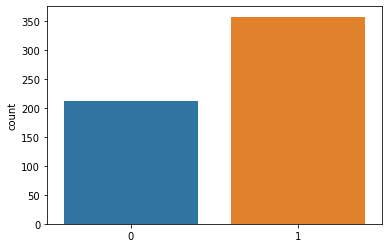

In [ ]:
# Leemos el conjunto de datos desde Sklearn
data = load_breast_cancer()

print('Características: ' + str(data.feature_names))
print('Resultados: ' + str(data.target_names))

x = data['data']
y = data['target']

sns.countplot(x = 'target', data=data)

print("Shape de la entrada: {}\nShape de la salida: {}".format(x.shape,y.shape))



Creamos dos conjuntos de datos el de entrenamiento (*train*) y el de test (*test*) para entrenar y probar la ANN, respectivamente.

Una buena práctica para facilitar el entrenamiento de las ANN es el normalizar los datos para que estén comprendidos en los intervalose [0, 1] o [-1, 1].

In [ ]:
# Dividimos el conjunto de datos para el entrenamiento y el test de la red
test_size = 0.2
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=test_size)

# Escalamos la entrada para que esté nomalizada
sc = StandardScaler()
x_train = sc.fit_transform(x_train)
x_test = sc.fit_transform(x_test)

PyTorch nos provee de una superclase/interfaz (Dataset) para que podamos crear una clase que lea los datos del conjunto de datos de forma más sencilla. Instanciándola podremos crear la nuestra.

In [ ]:
# Creamos una clase para Dataset los datos de forma automática
class dataset(Dataset):
  def __init__(self,x,y):
    self.x = torch.tensor(x,dtype=torch.float32)
    self.y = torch.tensor(y,dtype=torch.float32)
    #self.length = self.x.shape[0]

  def __getitem__(self,idx):
    return self.x[idx],self.y[idx]

  def __len__(self):
    return len(self.y)


PyTorch nos provee de la interfaz Net para que creemos nuestras propias arquitecturas.
Cramos una MLP para ser entrenada. Vemos que las capas intermedias tienen una función de activación ReLu y la capa de salida un Sigmoide para la clasificación binaria.

In [ ]:
class Net(nn.Module):

  def __init__(self, input_shape):
    super().__init__()
    # Definimos la arquitectura de la red
    self.fc1 = nn.Linear(input_shape,32)
    self.fc2 = nn.Linear(32,16)
    self.fc3 = nn.Linear(16,1)

  # Definimos como opera la red (una red feed-forward)
  def forward(self,x):
    x = torch.relu(self.fc1(x))
    x = torch.relu(self.fc2(x))
    x = torch.sigmoid(self.fc3(x))
    return x

net = Net(input_shape=x.shape[1])
print(net)


Net(
  (fc1): Linear(in_features=30, out_features=32, bias=True)
  (fc2): Linear(in_features=32, out_features=16, bias=True)
  (fc3): Linear(in_features=16, out_features=1, bias=True)
)


Definimos los parámetros que van a guiar el entrenamiento de la red

In [ ]:

# El tamaño del batch (cuantas muestras se van a leer en paralelo para actulizar la red)
batch_size = 64

# Creamos los conjuntos de datos
trainset = dataset(x_train,y_train)
testset = dataset(x_test,y_test)

trainset_size = len(trainset)
number_of_batches = int(trainset_size/batch_size) + 1

# Creamos los lectores de datos de cada conjunto de datos
trainloader = DataLoader(trainset,batch_size=batch_size,shuffle=True)
testloader = DataLoader(testset,batch_size=batch_size,shuffle=False)

In [ ]:
# Principales hiperparámetros
learning_rate = 0.002
epochs = 500
loss_fn = nn.BCELoss()

# Model , Optimizer, Loss
model = Net(input_shape=x.shape[1])
optimizer = torch.optim.SGD(model.parameters(),lr=learning_rate)

Entrenamos la red

In [ ]:
# Variables auxiliares
losses = []
accur = []

print('Training with {} of size {}.'.format(number_of_batches, batch_size))
print('Start training.....')

model.train()

# Bucle principal de entrenamiento
for epoch in range(epochs):

  # Bucle sobre el conjunto de datos leyendo batches para actualizar los pesos de la red
  for batch_number,(x,y) in enumerate(trainloader):

    # Calculamos la salida de la red dada la entrada
    output = model(x)

    # Calculamos la pérdida de la red (loss)
    loss = loss_fn(output,y.reshape(-1,1))

    # Calculamos estadísticas de precision
    predicted = model(torch.tensor(x_train,dtype=torch.float32))
    acc = (predicted.reshape(-1).detach().numpy().round() == y_train).mean()

    # Propagamos el error y actualizamos los pesos de la ANN
    optimizer.zero_grad()
    loss.backward()
    optimizer.step()


  if epoch%25 == 0:
    losses.append(loss.item())
    accur.append(acc)
    print("Epoch {}\tLoss : {}\t Accuracy : {}".format(epoch,loss,acc))

Training with 8 of size 64.
Start training.....
Epoch 0	Loss : 0.7065092921257019	 Accuracy : 0.43956043956043955
Epoch 25	Loss : 0.6433735489845276	 Accuracy : 0.8175824175824176
Epoch 50	Loss : 0.5944830179214478	 Accuracy : 0.8373626373626374
Epoch 75	Loss : 0.554268479347229	 Accuracy : 0.865934065934066
Epoch 100	Loss : 0.5760802626609802	 Accuracy : 0.8813186813186813
Epoch 125	Loss : 0.42392870783805847	 Accuracy : 0.9054945054945055
Epoch 150	Loss : 0.3670818507671356	 Accuracy : 0.9230769230769231
Epoch 175	Loss : 0.3131257891654968	 Accuracy : 0.9318681318681319
Epoch 200	Loss : 0.32372942566871643	 Accuracy : 0.9384615384615385
Epoch 225	Loss : 0.1558419018983841	 Accuracy : 0.9516483516483516
Epoch 250	Loss : 0.15334634482860565	 Accuracy : 0.9538461538461539
Epoch 275	Loss : 0.26108649373054504	 Accuracy : 0.9538461538461539
Epoch 300	Loss : 0.25563952326774597	 Accuracy : 0.9626373626373627
Epoch 325	Loss : 0.11980191618204117	 Accuracy : 0.967032967032967
Epoch 350	Loss 

Mostramos algunas estadísticas: Evolución de la pérdida, evolución de la precisión y precisión sobre los datos de test.

Text(0, 0.5, 'loss')

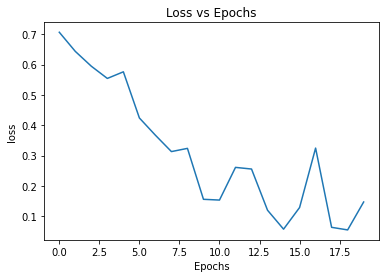

In [ ]:
# Mostramos la evolución de la pérdida
plt.plot(losses)
plt.title('Loss vs Epochs')
plt.xlabel('Epochs')
plt.ylabel('loss')

Text(0, 0.5, 'loss')

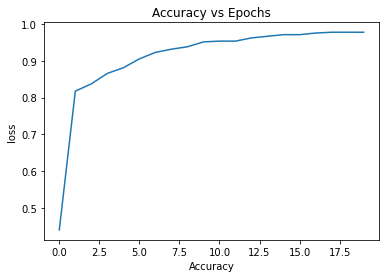

In [ ]:
# Mostramos la evolución de la pérdida
plt.plot(accur)
plt.title('Accuracy vs Epochs')
plt.xlabel('Accuracy')
plt.ylabel('loss')

In [ ]:
# Mostramos la precisión de la ANN en los datos de test
model.eval()
predicted = model(torch.tensor(x_test,dtype=torch.float32))
acc = (predicted.reshape(-1).detach().numpy().round() == y_test).mean()
print(acc)

0.956140350877193
